In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm

#find the project root
ROOT=Path.cwd()
while not (ROOT / ".git").exists() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from config import START_YEAR, END_YEAR, HOLDOUT_START, MP_THRESHOLD, MIN_GAMES_SHARE, MIN_MP
import utils

df_tot=utils.player_stat_dataframe(START_YEAR, END_YEAR)
df_tot.shape

(24992, 36)

In [2]:
df_holdout=df_tot[df_tot['Year'] >= HOLDOUT_START].copy() #locked away until the very end
df_tot=df_tot[df_tot['Year'] < HOLDOUT_START].copy() #everything below uses only this
print(df_tot['Year'].max(), "last development season") #should be 2018

2018 last development season


In [3]:
#1 on every row of a player traded mid-season (his 2TM/3TM total row and each team row)
is_total=df_tot['Team'].str.endswith('TM')
df_tot['TradedMidSeason']=is_total.groupby([df_tot['Year'], df_tot['Code']]).transform('any').astype(int)

#season length = most games any single-team player played that season (50 in 1998-99, 66 in 2011-12, ...)
season_games=df_tot[~is_total].groupby('Year')['G'].max()
df_tot['SeasonG']=df_tot['Year'].map(season_games)
df_tot['GP%']=df_tot['G'] / df_tot['SeasonG']      #replaces the loader's G/82 version

#keep one row per player-season: single-team players keep their row, traded players only keep their total row
season_rows=df_tot[(df_tot['TradedMidSeason']== 0) | is_total]

#MVP eligibility, step 1 of the two-step model:the CBA rule since 2023-24 is 65 games with 20+ minutes.
#This is applied to EVERY season, scaled to season length(40 of 50 games in 1998-99, 53 of 66 in 2011-12..)because voters already kinda behaved this way (see the check in the next cell).
#Our data only has season averages, so 20+ mins == MP >=20 per game, and the rule's injury exceptions aren't modeled.-->could keep 60+ games if we want to account fir injuries etc
min_games=np.ceil(MIN_GAMES_SHARE * season_rows['SeasonG'])
eligible=(season_rows['G'] >= min_games) & (season_rows['MP'] >= MIN_MP)

data=season_rows[eligible].reset_index(drop=True)

print(data.shape)
print(data.duplicated(['Year', 'Code']).sum(), "duplicate player-seasons")
print((data['MVPVS'] > 0).sum(), "vote-getter rows")
print(data.groupby('Year')['MVP'].sum().eq(1).all(), "every season still has its MVP")

(6287, 38)
0 duplicate player-seasons
610 vote-getter rows
True every season still has its MVP


In [4]:
#check: which vote-getters does the rule remove, and did any of them finish top 3?
removed=season_rows[~eligible & (season_rows['MVPVS'] > 0)]
vote_rank=season_rows.groupby('Year')['MVPVS'].rank(ascending=False, method='min')
share=removed['MVPVS'].sum() / season_rows['MVPVS'].sum() * 100
print(len(removed), f'vote-getters removed, with {share:.1f}% of all vote share')
print((vote_rank[removed.index] <= 3).sum(), 'of them finished top 3')
removed.sort_values('MVPVS', ascending=False)[['Year', 'Player', 'G', 'SeasonG', 'MP', 'MVPVS']].head(10)

39 vote-getters removed, with 0.8% of all vote share
0 of them finished top 3


,Year,Player,G,SeasonG,MP,MVPVS
7315,1997,Shaquille O'Neal,60.0,82.0,36.3,0.268
1476,1984,Bernard King,55.0,82.0,37.5,0.090
6202,1995,Shaquille O'Neal,54.0,82.0,36.0,0.056
19240,2018,Joel Embiid,64.0,82.0,33.7,0.049
16141,2013,Chris Paul,62.0,82.0,35.0,0.036
9405,2001,Chris Webber,54.0,82.0,38.4,0.029
10,1980,Magic Johnson,37.0,82.0,37.1,0.026
3921,1990,Larry Bird,60.0,82.0,38.0,0.026
9407,2001,Allen Iverson,60.0,82.0,43.7,0.023
374,1981,Dan Roundfield,61.0,82.0,36.3,0.020


In [5]:
#now feature lists and within season z-scores
feature_sets = {
    'heatmap_8':        ['PTS', 'W%', 'FT', 'eFG%', 'TRB', 'AST', 'BLK', 'STL'],
    'candidates_10':    ['PTS', 'W%', 'FT', 'eFG%', 'DRB', 'AST', 'BLK', 'STL', 'GS', '3P'],
    'rf_recall_6':      ['PTS', 'W%', 'eFG%', 'DRB', 'AST', 'BLK'],
}
#rf_recall_6 comes from the model_exploration nb which scored each subset on 2019-2025, so the results from this may be slightly more optimistic compared to the other 2
all_feats=sorted(set().union(*feature_sets.values()))

#within-season z-score for each feature: (value - season mean) / season std, then check no NaNs
for col in all_feats:
    g=data.groupby('Year')[col]
    data[col + '_z']=(data[col] - g.transform('mean'))/g.transform('std')

print(data[[c + '_z' for c in all_feats]].isna().sum())

3P_z      0
AST_z     0
BLK_z     0
DRB_z     0
FT_z      0
GS_z      0
PTS_z     0
STL_z     0
TRB_z     0
W%_z      0
eFG%_z    0
dtype: int64


### Quasi-binomial regression for MVP vote share

For each player-season, the model computes a linear score from the within-season z-scored features, then converts it to a predicted vote share between 0 and 1:
$$\text{score} = b_0 + b_1\,\text{PTS}_z + b_2\,\text{W\%}_z + \dots + b_k\,\text{STL}_z$$

$$\text{vote share} = \frac{1}{1 + e^{-\text{score}}}$$

- $b_0$ is the intercept: the score of a player at the season average in every feature.
- Each $b_i$ shows how much one standard deviation in that feature changes the score; $e^{b_i}$ is the multiplier on the odds.
- `scale='X2'` makes it quasi-binomial: the coefficients are the same as a binomial fit, but the dispersion is estimated from the data, so the standard errors and p-values are realistic.

In [6]:
fits={}
for name, feats in feature_sets.items():
    zf=[c + '_z' for c in feats]
    X=sm.add_constant(data[zf])
    fits[name]=sm.GLM(data['MVPVS'], X, family=sm.families.Binomial()).fit(scale='X2')  #quasi-binomial
    print(f"\n===== {name} (dispersion {fits[name].scale:.4f})")
    print(fits[name].summary())


===== heatmap_8 (dispersion 0.0278)
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  MVPVS   No. Observations:                 6287
Model:                            GLM   Df Residuals:                     6278
Model Family:                Binomial   Df Model:                            8
Link Function:                  Logit   Scale:                        0.027767
Method:                          IRLS   Log-Likelihood:                -148.06
Date:                Tue, 10 Nov 2026   Deviance:                       106.22
Time:                        17:00:26   Pearson chi2:                     174.
No. Iterations:                    13   Pseudo R-squ. (CS):            0.09879
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -

In [7]:
def evaluate(df, score_col):
    hits, ranks=0, []
    for yr,g in df.groupby('Year'):
        assert g['MVP'].sum() == 1, f"{yr}: expected exactly one MVP, found {g['MVP'].sum()}"
        actual=g.loc[g['MVP'].idxmax(), 'Code']
        order=g.sort_values(score_col, ascending=False)['Code'].tolist()
        hits+=order[0] == actual #True gets 1
        ranks.append(order.index(actual) +1) #so top position is 1 and not 0
    print(f"{score_col}: picked MVP in {hits}/{len(ranks)} seasons,", f"real winner's avg rank={np.mean(ranks):.2f}")


In [8]:
import warnings
warnings.filterwarnings('ignore')   #hides repeated warnings from the fits

MIN_HISTORY=10 #seasons of training data before any predictions
years=sorted(data['Year'].unique())
test_years=years[MIN_HISTORY:] #1990 onward

for name, feats in feature_sets.items():
    zf=[c + '_z' for c in feats]
    col=f'pred_{name}'
    data[col]=np.nan

    for yr in test_years:
        train=data['Year'] < yr #only seasons before the test season
        test=data['Year'] == yr
        assert data.loc[train, 'Year'].max() < yr
        model=sm.GLM(data.loc[train, 'MVPVS'], sm.add_constant(data.loc[train, zf]),
                     family=sm.families.Binomial()).fit(scale='X2')
        data.loc[test, col]=model.predict(sm.add_constant(data.loc[test, zf], has_constant='add'))

tested=data[data['Year'].isin(test_years)]    #runs once, after all fits
for name in feature_sets:
    evaluate(tested, f'pred_{name}')
evaluate(tested, 'PTS')    #baseline, once

pred_heatmap_8: picked MVP in 18/29 seasons, real winner's avg rank=1.93
pred_candidates_10: picked MVP in 17/29 seasons, real winner's avg rank=1.90
pred_rf_recall_6: picked MVP in 18/29 seasons, real winner's avg rank=1.86
PTS: picked MVP in 10/29 seasons, real winner's avg rank=5.28


In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor

for name, feats in feature_sets.items():
    for kind, cols in [('raw', feats), ('z', [c + '_z' for c in feats])]:
        col=f'gbr_{kind}_{name}'
        data[col]=np.nan
        for yr in test_years:
            train=data['Year'] < yr
            test=data['Year'] == yr
            assert data.loc[train, 'Year'].max() < yr
            model=HistGradientBoostingRegressor(random_state=12)
            model.fit(data.loc[train, cols], data.loc[train, 'MVPVS'])
            data.loc[test, col]=model.predict(data.loc[test, cols])

tested=data[data['Year'].isin(test_years)]      #rebuild so it includes the new gbr_ columns
for col in [c for c in data.columns if c.startswith(('pred_', 'gbr_'))]:
    evaluate(tested, col)


pred_heatmap_8: picked MVP in 18/29 seasons, real winner's avg rank=1.93
pred_candidates_10: picked MVP in 17/29 seasons, real winner's avg rank=1.90
pred_rf_recall_6: picked MVP in 18/29 seasons, real winner's avg rank=1.86
gbr_raw_heatmap_8: picked MVP in 24/29 seasons, real winner's avg rank=2.00
gbr_z_heatmap_8: picked MVP in 22/29 seasons, real winner's avg rank=1.69
gbr_raw_candidates_10: picked MVP in 22/29 seasons, real winner's avg rank=1.86
gbr_z_candidates_10: picked MVP in 20/29 seasons, real winner's avg rank=1.86
gbr_raw_rf_recall_6: picked MVP in 21/29 seasons, real winner's avg rank=1.83
gbr_z_rf_recall_6: picked MVP in 20/29 seasons, real winner's avg rank=1.79


In [10]:
#every MVP in the development seasons, as (season, player ID) pairs
mvp_rows=df_tot[df_tot['MVP']==1]
winners=set(zip(mvp_rows['Year'], mvp_rows['Code']))

#recency-weighted past MVPs: a win last season counts 1, two seasons ago 0.5, three seasons ago 0.25, and so on
from collections import defaultdict
wins=defaultdict(list)
for y, c in winners:
    wins[c].append(y)

data['MVP_recency']=[sum(0.5 ** (y - w - 1) for w in wins[c] if w < y)
                     for y, c in zip(data['Year'], data['Code'])]

#check: Jordan's values in 1992 and 1996
data.loc[data['Player']=='Michael Jordan', ['Year', 'MVP_recency', 'MVPVS', 'MVP']]

,Year,MVP_recency,MVPVS,MVP
586,1984,0.000000,0.172,0
862,1986,0.000000,0.576,0
1000,1987,0.000000,0.831,1
1144,1988,1.000000,0.704,0
1300,1989,0.500000,0.613,0
1465,1990,0.250000,0.928,1
1629,1991,1.125000,0.938,1
1789,1992,1.562500,0.577,0
2257,1995,0.195312,0.986,1
2427,1996,1.097656,0.832,0


In [11]:
past=['MVP_recency'] #kept raw, not z-scored

for name, feats in feature_sets.items():
    q_cols=[c + '_z' for c in feats] + past
    g_cols=feats + past
    data[f'pred_past_{name}']=np.nan
    data[f'gbr_past_{name}']=np.nan

    for yr in test_years:
        train=data['Year'] < yr
        test=data['Year'] == yr
        assert data.loc[train, 'Year'].max() < yr
        qb=sm.GLM(data.loc[train, 'MVPVS'], sm.add_constant(data.loc[train, q_cols]),
                  family=sm.families.Binomial()).fit(scale='X2')
        data.loc[test, f'pred_past_{name}']=qb.predict(sm.add_constant(data.loc[test, q_cols], has_constant='add'))
        gb=HistGradientBoostingRegressor(random_state=12).fit(data.loc[train, g_cols], data.loc[train, 'MVPVS'])
        data.loc[test, f'gbr_past_{name}']=gb.predict(data.loc[test, g_cols])

tested=data[data['Year'].isin(test_years)]
for name in feature_sets:
    for col in [f'pred_{name}', f'pred_past_{name}', f'gbr_raw_{name}', f'gbr_past_{name}']:
        evaluate(tested, col)
    print()

pred_heatmap_8: picked MVP in 18/29 seasons, real winner's avg rank=1.93
pred_past_heatmap_8: picked MVP in 18/29 seasons, real winner's avg rank=1.93
gbr_raw_heatmap_8: picked MVP in 24/29 seasons, real winner's avg rank=2.00
gbr_past_heatmap_8: picked MVP in 21/29 seasons, real winner's avg rank=1.86

pred_candidates_10: picked MVP in 17/29 seasons, real winner's avg rank=1.90
pred_past_candidates_10: picked MVP in 17/29 seasons, real winner's avg rank=1.90
gbr_raw_candidates_10: picked MVP in 22/29 seasons, real winner's avg rank=1.86
gbr_past_candidates_10: picked MVP in 19/29 seasons, real winner's avg rank=1.79

pred_rf_recall_6: picked MVP in 18/29 seasons, real winner's avg rank=1.86
pred_past_rf_recall_6: picked MVP in 18/29 seasons, real winner's avg rank=1.86
gbr_raw_rf_recall_6: picked MVP in 21/29 seasons, real winner's avg rank=1.83
gbr_past_rf_recall_6: picked MVP in 20/29 seasons, real winner's avg rank=1.79



In [12]:
qb_all=sm.GLM(data['MVPVS'], sm.add_constant(data[[c + '_z' for c in feature_sets['candidates_10']] + ['MVP_recency']]),
              family=sm.families.Binomial()).fit(scale='X2')
print(qb_all.summary().tables[1])

                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -9.5797      0.127    -75.487      0.000      -9.828      -9.331
PTS_z           1.5284      0.048     31.555      0.000       1.433       1.623
W%_z            1.9173      0.044     43.473      0.000       1.831       2.004
FT_z            0.2558      0.035      7.308      0.000       0.187       0.324
eFG%_z          0.3231      0.029     11.330      0.000       0.267       0.379
DRB_z           0.4978      0.027     18.530      0.000       0.445       0.550
AST_z           0.7320      0.025     29.669      0.000       0.684       0.780
BLK_z           0.2575      0.025     10.331      0.000       0.209       0.306
STL_z           0.2278      0.025      9.281      0.000       0.180       0.276
GS_z            0.4114      0.104      3.968      0.000       0.208       0.615
3P_z           -0.0640      0.025     -2

from the last line in the table--> MVP_recency = 0.155, p = 0.016 → e^0.155 ≈ 1.17, so a reigning MVP (with recency=1) has about 17% higher odds of vote share than a player with identical stats and no recent MVP. It doesn't improve picking the winner in forward-chaining.

In [13]:
from statsmodels.discrete.conditional_models import ConditionalLogit

#conditional logit--> within each season, which player wins? (MVP = 1 for the winner, 0 otherwise)
clogit_cols=[c + '_z' for c in feature_sets['candidates_10']] + ['MVP_recency']
clogit=ConditionalLogit(data['MVP'], data[clogit_cols], groups=data['Year']).fit(maxiter=200)
print(clogit.summary())

                  Conditional Logit Model Regression Results                  
Dep. Variable:                    MVP   No. Observations:                 6287
Model:               ConditionalLogit   No. groups:                         39
Log-Likelihood:               -26.421   Min group size:                    135
Method:                          BFGS   Max group size:                    179
Date:                Tue, 10 Nov 2026   Mean group size:                 161.2
Time:                        17:06:41                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
PTS_z           3.8896      1.175      3.310      0.001       1.587       6.193
W%_z            5.4842      1.280      4.286      0.000       2.976       7.992
FT_z           -0.0623      0.403     -0.155      0.877      -0.852       0.727
eFG%_z         -0.2037      0.436     -0.468   

In the conditional logit (who wins)--> MVP_recency = −0.60 (p = 0.32) → e^−0.60 ≈ 0.55: recent MVPs look about 45% less likely to win at the same stats (voter fatigue), but with only 39 seasons this isn't statistically significant.

In [14]:
#forward-chaining conditional logit: for each test season, train only on earlier seasons
def forward_clogit(df, cols, col_name):
    df[col_name]=np.nan
    biggest={}     #largest coefficient per test season, to check stability (smaller num=more stable)
    for yr in test_years:
        train=df['Year'] < yr
        test=df['Year'] == yr
        assert df.loc[train, 'Year'].max() < yr
        res=ConditionalLogit(df.loc[train, 'MVP'], df.loc[train, cols],
                             groups=df.loc[train, 'Year']).fit(disp=False, skip_hessian=True, maxiter=200)
        df.loc[test, col_name]=df.loc[test, cols] @ res.params     #score = sum of weight x feature
        biggest[yr]=res.params.abs().max()
    return pd.Series(biggest)

base_cols=[c + '_z' for c in feature_sets['candidates_10']]
stab=forward_clogit(data, base_cols, 'clogit_candidates_10')
stab_past=forward_clogit(data, base_cols + ['MVP_recency'], 'clogit_past_candidates_10')

print(stab.round(1).to_string())

1990     63.5
1991     99.8
1992    101.4
1993     98.1
1994    101.7
1995     57.0
1996     59.5
1997     64.1
1998     10.6
1999     10.5
2000     10.8
2001      5.4
2002      5.6
2003      6.0
2004      6.1
2005      5.8
2006      4.8
2007      4.9
2008      5.2
2009      5.1
2010      5.2
2011      5.5
2012      4.9
2013      5.1
2014      5.1
2015      5.4
2016      5.4
2017      5.0
2018      5.0


In [15]:
#conditional logit fits are unstable before 2001 (fewer than ~20 winners to learn from--> see the stability numbers above), so I'm also comparing on 2001-2018

#compare all models: all test seasons (1990-2018) and the seasons where the conditional logit is stable (2001-2018)
compare=['clogit_candidates_10', 'clogit_past_candidates_10',
         'pred_candidates_10', 'gbr_raw_candidates_10', 'gbr_z_candidates_10', 'PTS']

for label, start in [('1990-2018', 1990), ('2001-2018 (stable conditional logit)', 2001)]:
    print(f"\n===== {label}")
    window=data[(data['Year'] >= start) & data['Year'].isin(test_years)]
    for col in compare:
        evaluate(window, col)


===== 1990-2018
clogit_candidates_10: picked MVP in 18/29 seasons, real winner's avg rank=1.90
clogit_past_candidates_10: picked MVP in 16/29 seasons, real winner's avg rank=1.90
pred_candidates_10: picked MVP in 17/29 seasons, real winner's avg rank=1.90
gbr_raw_candidates_10: picked MVP in 22/29 seasons, real winner's avg rank=1.86
gbr_z_candidates_10: picked MVP in 20/29 seasons, real winner's avg rank=1.86
PTS: picked MVP in 10/29 seasons, real winner's avg rank=5.28

===== 2001-2018 (stable conditional logit)
clogit_candidates_10: picked MVP in 13/18 seasons, real winner's avg rank=1.89
clogit_past_candidates_10: picked MVP in 12/18 seasons, real winner's avg rank=1.83
pred_candidates_10: picked MVP in 11/18 seasons, real winner's avg rank=2.17
gbr_raw_candidates_10: picked MVP in 12/18 seasons, real winner's avg rank=2.33
gbr_z_candidates_10: picked MVP in 11/18 seasons, real winner's avg rank=2.28
PTS: picked MVP in 4/18 seasons, real winner's avg rank=7.28


# Visuals

Charts and tables for the slides and the executive summary. Everything is saved to `results/final/`.

- Results compare the three models on **2001–2018**: each season predicted by a model trained only on earlier seasons. Before 2001 the conditional logit has too few past winners to be stable (see the stability check above).
- The compared models use the **candidates_10** stats without MVP_recency (`pred_candidates_10`, `gbr_raw_candidates_10`, `clogit_candidates_10`).
- The 2019–2025 hold-out is **not** used anywhere in this section.

### Setup
Shared colors and helpers so all charts look the same. Run this first.

In [16]:
import matplotlib.pyplot as plt

#shared chart style for the presentation (light background, consistent colors)
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'

OUT = ROOT / 'results' / 'final'
OUT.mkdir(parents=True, exist_ok=True)   #creates results/final/ if it doesn't exist

def new_chart(figsize):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(AXIS)
    ax.tick_params(colors=MUTED, length=0)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    return fig, ax

def add_titles(fig, main, sub):
    fig.text(0.02, 0.96, main, fontsize=14, fontweight='bold', color=INK, va='top')
    fig.text(0.02, 0.89, sub, fontsize=10.5, color=INK2, va='top')

### A. How predictions are made
Forward-chaining: to predict a season, the model only sees seasons before it, so it never trains on the answer.

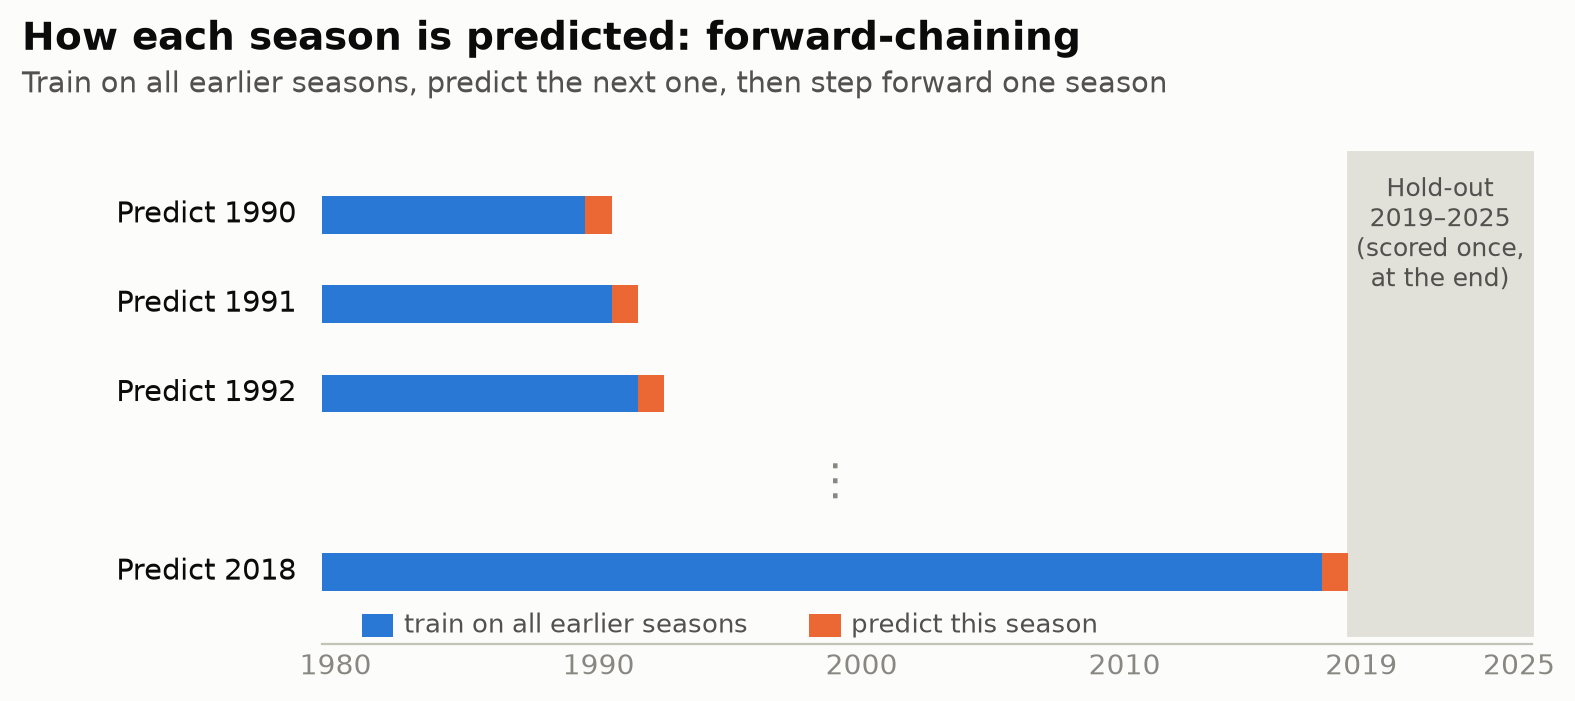

In [17]:
#forward-chaining diagram
from matplotlib.patches import Rectangle


def plot_forward_chaining(fname, start=1980, hold=HOLDOUT_START, end=2025):
    #rows: a few example test seasons; None draws the "..." gap
    rows = [(1990, 'Predict 1990'), (1991, 'Predict 1991'), (1992, 'Predict 1992'), (None, '...'), (2018, 'Predict 2018')]
    fig, ax = plt.subplots(figsize=(8, 3.6), dpi=200)
    fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

    #shaded hold-out block
    ax.add_patch(Rectangle((hold - 0.5, -0.7), end - hold + 1, len(rows) + 0.4, color=GRID, zorder=0))
    ax.text(hold + (end - hold) / 2, len(rows) - 0.55, f'Hold-out\n{hold}–{end}\n(scored once,\nat the end)',
            ha='center', va='top', fontsize=9, color=INK2)

    for i, (yr, label) in enumerate(rows):
        y = len(rows) - 1 - i                                   #top row first
        if yr is None:
            ax.text(1999, y, '⋮', ha='center', va='center', fontsize=16, color=MUTED)
            continue
        ax.barh(y, yr - start, left=start - 0.5, height=0.42, color=BLUE)     #training seasons
        ax.barh(y, 1, left=yr - 0.5, height=0.42, color=ORANGE)               #the predicted season
        ax.text(start - 1.5, y, label, ha='right', va='center', fontsize=10.5, color=INK)

    ax.set_xlim(start - 12, end + 1); ax.set_ylim(-0.8, len(rows) - 0.2)
    ax.set_yticks([]); ax.set_xticks([1980, 1990, 2000, 2010, hold, end])
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(AXIS); ax.spines['bottom'].set_bounds(start - 0.5, end + 0.5)
    ax.tick_params(colors=MUTED, length=0)

    #legend drawn as small bars, so it matches the marks exactly
    ax.barh(-0.6, 1.2, left=1981, height=0.25, color=BLUE)
    ax.text(1982.6, -0.6, 'train on all earlier seasons', va='center', fontsize=9.5, color=INK2)
    ax.barh(-0.6, 1.2, left=1998, height=0.25, color=ORANGE)
    ax.text(1999.6, -0.6, 'predict this season', va='center', fontsize=9.5, color=INK2)

    add_titles(fig, 'How each season is predicted: forward-chaining',
               'Train on all earlier seasons, predict the next one, then step forward one season')
    fig.tight_layout(rect=(0, 0, 1, 0.83))
    fig.savefig(OUT / fname, facecolor=SURFACE)
    plt.show()

plot_forward_chaining('forward_chaining.png')


### B. How often each model picks the MVP
**Main KPI:** seasons where the model's #1 pick was the real MVP. **Secondary:** seasons where the real MVP was in the model's top 3.
Result: the conditional logit picks 13/18, gradient boosting 12/18, the quasi-binomial 11/18, and the "top scorer wins" baseline 4/18.

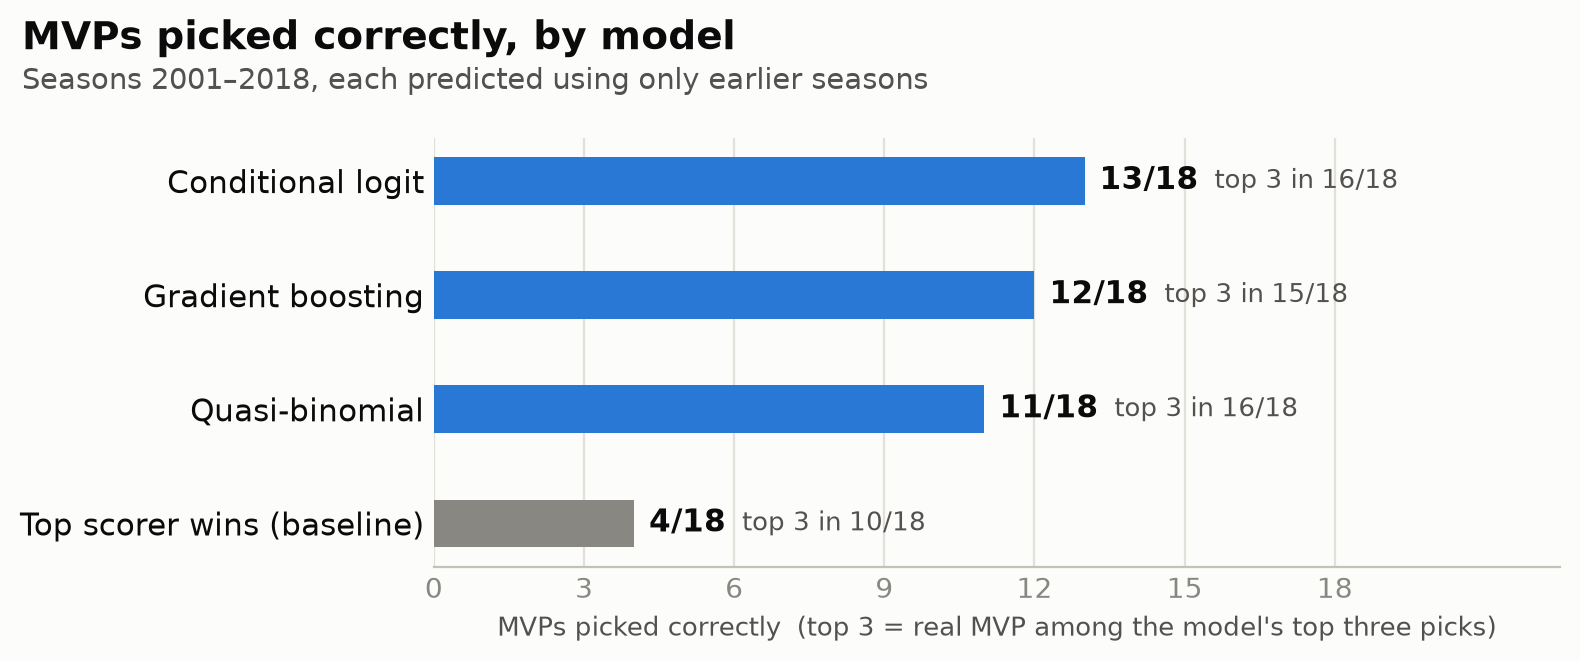

In [18]:
#how many MVPs each model picked correctly (and how often the real MVP was in its top 3)
def score(df, col):
    #hits = real MVP ranked 1st; top3 = real MVP ranked in the model's top 3
    hits, top3 = 0, 0
    for yr, g in df.groupby('Year'):
        actual = g.loc[g['MVP'].idxmax(), 'Code']
        order = g.sort_values(col, ascending=False)['Code'].tolist()
        rank = order.index(actual) + 1
        hits += rank == 1
        top3 += rank <= 3
    return hits, df['Year'].nunique(), top3

def plot_model_comparison(df, models, main, sub, fname):
    rows = [(label, *score(df, col)) for label, col in models.items()]
    fig, ax = new_chart((8, 3.4))
    bars = ax.barh([r[0] for r in rows], [r[1] for r in rows], height=0.42,
                   color=[MUTED if 'baseline' in r[0] else BLUE for r in rows])
    for b, (label, hits, n, top3) in zip(bars, rows):
        t = ax.text(hits + 0.3, b.get_y() + b.get_height()/2, f'{hits}/{n}',
                    va='center', color=INK, fontsize=11, fontweight='bold')
        ax.annotate(f'  top 3 in {top3}/{n}', xy=(1, 0.5), xycoords=t, va='center', color=INK2, fontsize=9.5)
    n = rows[0][2]
    ax.set_xlim(0, n + 4.5); ax.set_xticks(range(0, n + 1, 3))
    ax.tick_params(axis='y', colors=INK, labelsize=11)
    ax.set_xlabel("MVPs picked correctly  (top 3 = real MVP among the model's top three picks)", color=INK2, fontsize=9.5)
    add_titles(fig, main, sub)
    fig.tight_layout(rect=(0, 0, 1, 0.83))
    fig.savefig(OUT / fname, facecolor=SURFACE)
    plt.show()

#bottom-to-top order on the chart
models = {'Top scorer wins (baseline)': 'PTS',
          'Quasi-binomial': 'pred_candidates_10',
          'Gradient boosting': 'gbr_raw_candidates_10',
          'Conditional logit': 'clogit_candidates_10'}
#the three models without the baseline, with short tags for file names
short = {'Quasi-binomial': 'quasi', 'Gradient boosting': 'gb', 'Conditional logit': 'clogit'}
window = data[(data['Year'] >= 2001) & data['Year'].isin(test_years)]
plot_model_comparison(window, models,
                      'MVPs picked correctly, by model',
                      'Seasons 2001–2018, each predicted using only earlier seasons',
                      'model_comparison_2001_2018.png')

### C. Which seasons each model missed
One table per model (who it picked, their points / team win %, and where it ranked the real MVP), then one table with every model's misses side by side.
All three models missed 2004–05 and 2005–06 (Nash) and 2016–17 (Westbrook). Those are seasons where voters rewarded something our stats don't capture well (a pass-first point guard, a triple-double season).
2014–15 (Curry) is missed by both the quasi-binomial and gradient boosting, which picked Harden; only the conditional logit got it.

In [19]:
#misses table
def misses_table(df, col):
    """Seasons where the model's top pick wasn't the real MVP: who it picked, who won, and where it ranked the winner."""
    rows = []
    for yr, g in df.groupby('Year'):
        g = g.sort_values(col, ascending=False).reset_index(drop=True)   #row 0 = model's top pick
        winner = g[g['MVP'] == 1].iloc[0]
        pick = g.iloc[0]
        if pick['Code'] != winner['Code']:
            rows.append({'Season': f"{yr}–{str(yr + 1)[-2:]}",            #e.g. 2004 -> "2004–05"
                         'Model picked': pick['Player'],
                         'Picked: PTS / W%': f"{pick['PTS']:.1f} / {pick['W%']:.3f}",
                         'Actual MVP': winner['Player'],
                         'MVP: PTS / W%': f"{winner['PTS']:.1f} / {winner['W%']:.3f}",
                         "MVP's rank in model": int(g.index[g['Code'] == winner['Code']][0]) + 1})
    return pd.DataFrame(rows)

In [20]:
#misses table for every model (same seasons as the comparison chart)

for name, col in models.items():
    if name not in short:          #skip the baseline
        continue
    m = misses_table(window, col)
    m.to_csv(OUT / f'misses_{short[name]}_2001_2018.csv', index=False)
    print(f'\n===== {name}: missed {len(m)} of {window["Year"].nunique()} seasons')
    display(m)


===== Quasi-binomial: missed 7 of 18 seasons


,Season,Model picked,Picked: PTS / W%,Actual MVP,MVP: PTS / W%,MVP's rank in model
0,2002–03,Kobe Bryant,30.0 / 0.610,Tim Duncan,23.3 / 0.732,2
1,2004–05,Dirk Nowitzki,26.1 / 0.707,Steve Nash,15.5 / 0.756,11
2,2005–06,LeBron James,31.4 / 0.610,Steve Nash,18.8 / 0.659,7
3,2010–11,LeBron James,26.7 / 0.707,Derrick Rose,25.0 / 0.756,2
4,2014–15,James Harden,27.4 / 0.683,Stephen Curry,23.8 / 0.817,2
5,2016–17,James Harden,29.1 / 0.671,Russell Westbrook,31.6 / 0.573,2
6,2018–19,James Harden,36.1 / 0.646,Giannis Antetokounmpo,27.7 / 0.732,2



===== Gradient boosting: missed 6 of 18 seasons


,Season,Model picked,Picked: PTS / W%,Actual MVP,MVP: PTS / W%,MVP's rank in model
0,2001–02,Shaquille O'Neal,27.2 / 0.707,Tim Duncan,25.5 / 0.707,2
1,2002–03,Dirk Nowitzki,25.1 / 0.732,Tim Duncan,23.3 / 0.732,3
2,2004–05,Amar'e Stoudemire,26.0 / 0.756,Steve Nash,15.5 / 0.756,7
3,2005–06,Kobe Bryant,35.4 / 0.549,Steve Nash,18.8 / 0.659,12
4,2014–15,James Harden,27.4 / 0.683,Stephen Curry,23.8 / 0.817,2
5,2016–17,Stephen Curry,25.3 / 0.817,Russell Westbrook,31.6 / 0.573,4



===== Conditional logit: missed 5 of 18 seasons


,Season,Model picked,Picked: PTS / W%,Actual MVP,MVP: PTS / W%,MVP's rank in model
0,2004–05,Dirk Nowitzki,26.1 / 0.707,Steve Nash,15.5 / 0.756,6
1,2005–06,Chauncey Billups,18.5 / 0.780,Steve Nash,18.8 / 0.659,8
2,2011–12,Kevin Durant,28.0 / 0.712,LeBron James,27.1 / 0.697,2
3,2016–17,James Harden,29.1 / 0.671,Russell Westbrook,31.6 / 0.573,3
4,2018–19,James Harden,36.1 / 0.646,Giannis Antetokounmpo,27.7 / 0.732,2


In [21]:
#one table: each season at least one model missed, and who each model picked instead
rows = {}
for yr, g in window.groupby('Year'):
    rows[yr] = {'Actual MVP': g.loc[g['MVP'] == 1, 'Player'].iloc[0]}
    for name in short:
        pick = g.loc[g[models[name]].idxmax()]
        rows[yr][name] = '✓' if pick['MVP'] == 1 else pick['Player']

grid = pd.DataFrame.from_dict(rows, orient='index')
grid = grid[(grid[list(short)] != '✓').any(axis=1)]          #drop seasons all models got right
grid.index = [f"{y}–{str(y + 1)[-2:]}" for y in grid.index]   #2004 -> "2004–05"
grid.to_csv(OUT / 'misses_all_models_2001_2018.csv')
grid

,Actual MVP,Quasi-binomial,Gradient boosting,Conditional logit
2001–02,Tim Duncan,✓,Shaquille O'Neal,✓
2002–03,Tim Duncan,Kobe Bryant,Dirk Nowitzki,✓
2004–05,Steve Nash,Dirk Nowitzki,Amar'e Stoudemire,Dirk Nowitzki
2005–06,Steve Nash,LeBron James,Kobe Bryant,Chauncey Billups
2010–11,Derrick Rose,LeBron James,✓,✓
2011–12,LeBron James,✓,✓,Kevin Durant
2014–15,Stephen Curry,James Harden,James Harden,✓
2016–17,Russell Westbrook,James Harden,Stephen Curry,James Harden
2018–19,Giannis Antetokounmpo,James Harden,✓,James Harden


### D. What each model learned (1980–2018)
One chart per model, each fit on all development seasons **with** MVP_recency. These show what each model learned overall, not the season-by-season picks.

The three charts measure different things, so compare the order of the stats, not the numbers:
- **Conditional logit:** effect on the chance of *winning* (log-odds per 1 SD above the season average).
- **Quasi-binomial:** effect on *vote share*. With ~6,300 player-seasons every range is narrow, so judge by size, not color.
- **Gradient boosting:** permutation importance, meaning how much the fit drops when a stat is shuffled. It has no direction (it can't say whether a stat helps or hurts).

All three agree that team win % and points matter most.

In [22]:
#shared chart for "what each model learned": one dot + 95% range per stat, sorted, blue if the range is clear of zero
names = {'PTS_z': 'Points', 'W%_z': 'Team win %', 'FT_z': 'Free throws', 'eFG%_z': 'Shooting efficiency (eFG%)',
         'DRB_z': 'Defensive rebounds', 'AST_z': 'Assists', 'BLK_z': 'Blocks', 'STL_z': 'Steals',
         'GS_z': 'Games started', '3P_z': '3-pointers', 'MVP_recency': 'Recent MVP wins (per win)'}
def label(f):
    return names.get(f, names.get(f + '_z', f))

def plot_ranges(c, xlabel, main, sub, fname):
    # c: DataFrame indexed by feature, with columns est, lo, hi
    c = c.sort_values('est')
    clear = (c['lo'] > 0) | (c['hi'] < 0)          # range doesn't cross zero
    fig, ax = new_chart((8, 4.6))
    ax.axvline(0, color=AXIS, linewidth=1.2, zorder=1)
    for i, (feat, r) in enumerate(c.iterrows()):
        col = BLUE if clear[feat] else MUTED
        ax.plot([r.lo, r.hi], [i, i], color=col, linewidth=2, solid_capstyle='round', zorder=2)
        ax.scatter(r.est, i, s=70, color=col, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.set_yticks(range(len(c)))
    ax.set_yticklabels([label(f) for f in c.index])
    for lab, feat in zip(ax.get_yticklabels(), c.index):
        lab.set_color(INK if clear[feat] else MUTED)
    ax.set_xlabel(xlabel, color=INK2, fontsize=9.5)
    add_titles(fig, main, sub)
    fig.tight_layout(rect=(0, 0, 1, 0.87))
    fig.savefig(OUT / fname, facecolor=SURFACE)
    plt.show()

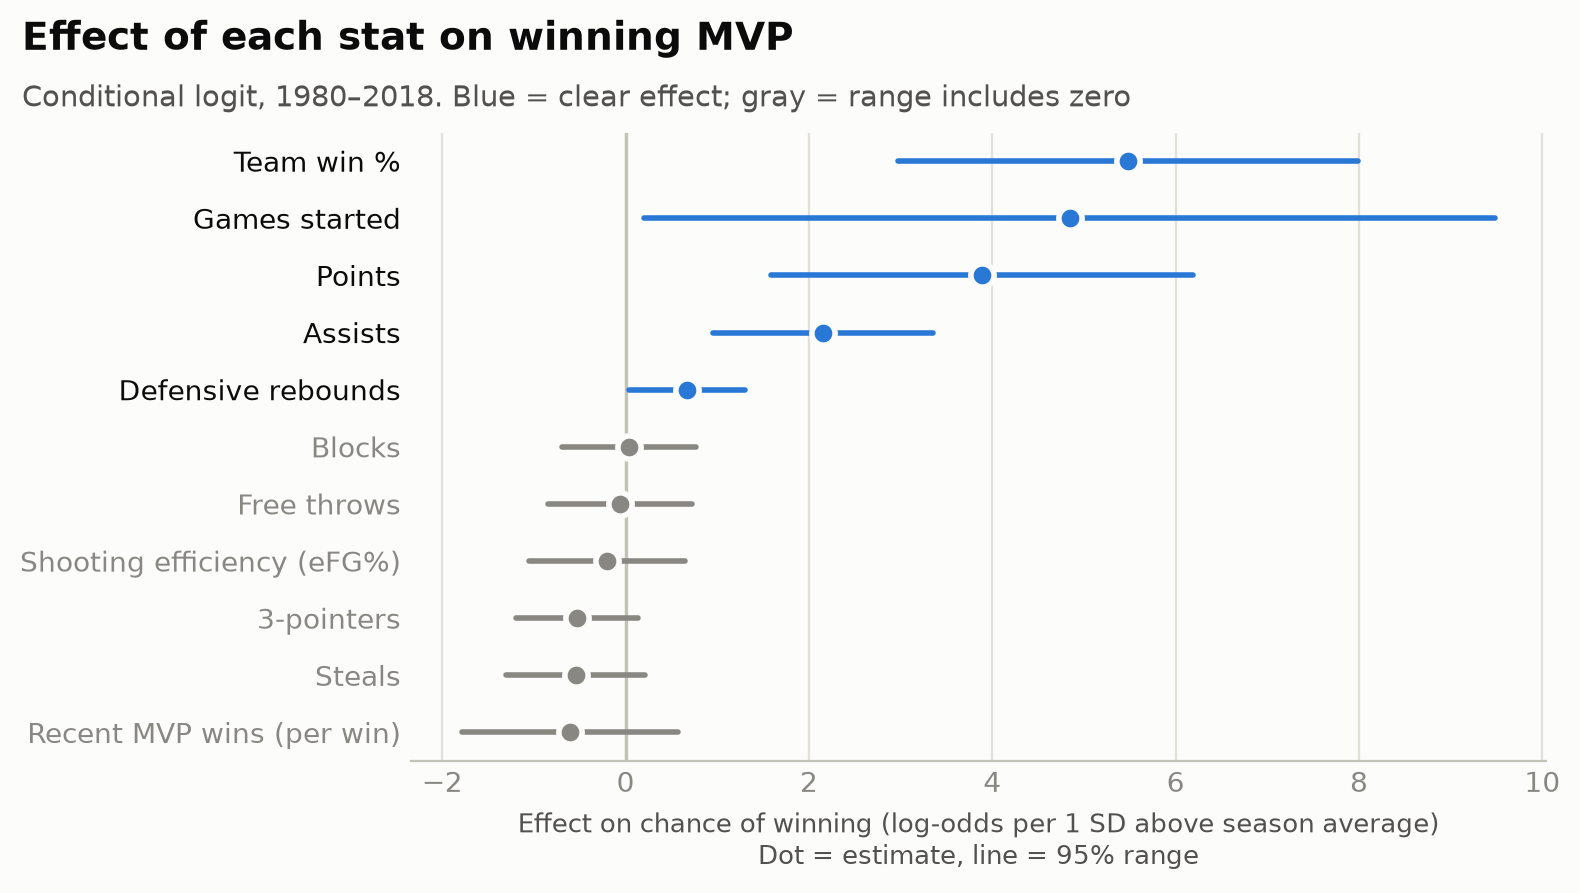

In [23]:
#conditional logit: effect of each stat on winning
ci = clogit.conf_int()
c = pd.DataFrame({'est': clogit.params, 'lo': ci[0], 'hi': ci[1]})
plot_ranges(c,
    'Effect on chance of winning (log-odds per 1 SD above season average)\nDot = estimate, line = 95% range',
    'Effect of each stat on winning MVP',
    'Conditional logit, 1980–2018. Blue = clear effect; gray = range includes zero',
    'what_wins_mvp.png')

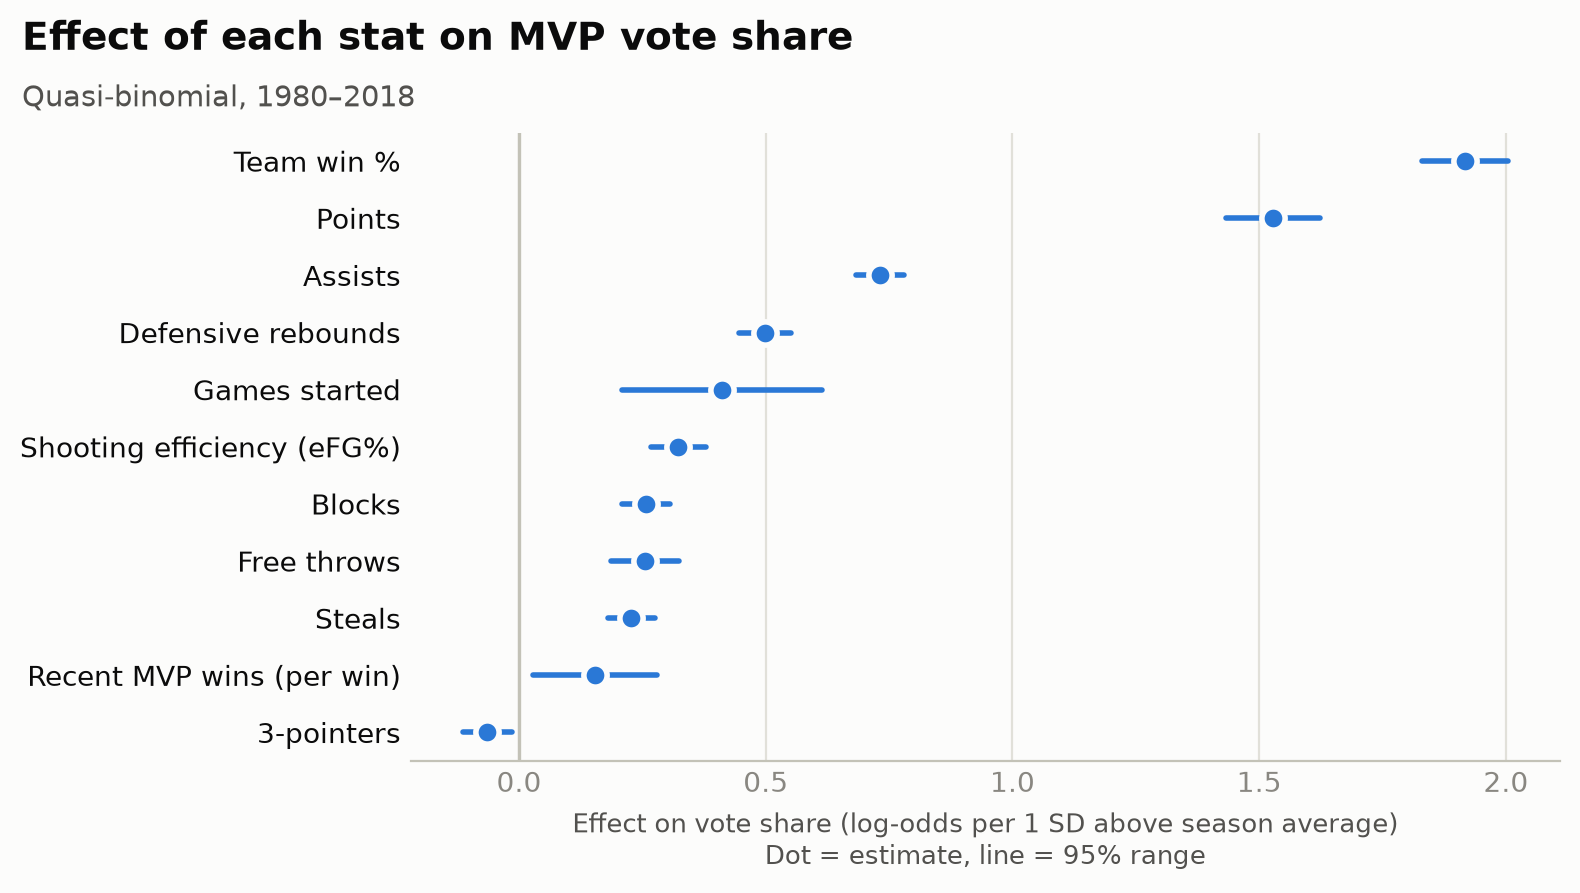

In [24]:
ci = qb_all.conf_int()
c = pd.DataFrame({'est': qb_all.params, 'lo': ci[0], 'hi': ci[1]}).drop('const')

plot_ranges(c,
    'Effect on vote share (log-odds per 1 SD above season average)\nDot = estimate, line = 95% range',
    'Effect of each stat on MVP vote share',
    'Quasi-binomial, 1980–2018',
    'effects_quasi.png')

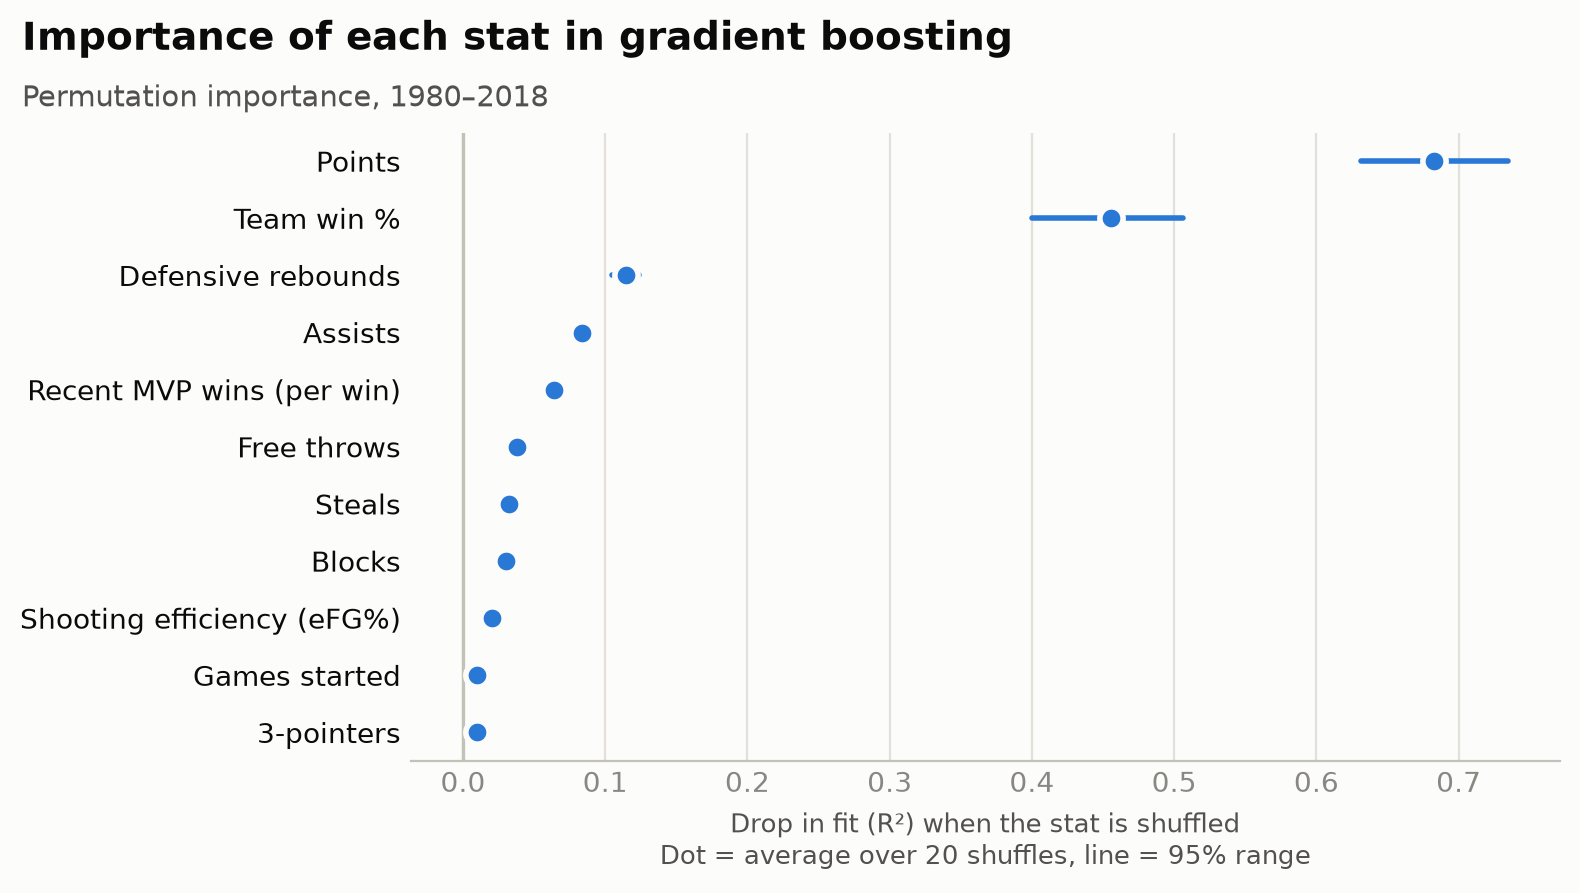

In [25]:
from sklearn.inspection import permutation_importance

gcols = feature_sets['candidates_10'] + ['MVP_recency']     # raw candidates_10, same as gbr_raw_candidates_10
gb = HistGradientBoostingRegressor(random_state=12).fit(data[gcols], data['MVPVS'])
#measured on the training seasons, so it shows what the model relies on, not how well it predicts
r = permutation_importance(gb, data[gcols], data['MVPVS'], n_repeats=20, random_state=12)

c = pd.DataFrame({'est': r.importances_mean,
                  'lo':  np.percentile(r.importances, 2.5, axis=1),
                  'hi':  np.percentile(r.importances, 97.5, axis=1)}, index=gcols)

plot_ranges(c,
    'Drop in fit (R²) when the stat is shuffled\nDot = average over 20 shuffles, line = 95% range',
    'Importance of each stat in gradient boosting',
    'Permutation importance, 1980–2018',
    'importance_gb.png')

### E. Why each model picked who it picked
Every model gives each player a score, and the pick is the highest score. Each score splits exactly into one piece per stat: coefficient × z-score for the two linear models, SHAP values for gradient boosting. We use the model that actually made each season's pick (trained only on earlier seasons), and check that it reproduces the predictions above.

Requires `shap` (`conda install -c conda-forge shap`).

In [26]:
#refit the exact models behind the comparison chart (candidates_10, no MVP_recency), one per test season, and keep them
feats10 = feature_sets['candidates_10']        #raw stats, for gradient boosting
z10 = [c + '_z' for c in feats10]              #z-scores, for quasi-binomial and conditional logit

season_models = {}     #season -> {model name: model trained only on earlier seasons}
for yr in test_years:
    train = data['Year'] < yr
    assert data.loc[train, 'Year'].max() < yr
    season_models[yr] = {
        'Quasi-binomial': sm.GLM(data.loc[train, 'MVPVS'], sm.add_constant(data.loc[train, z10]),
                                 family=sm.families.Binomial()).fit(scale='X2'),
        'Gradient boosting': HistGradientBoostingRegressor(random_state=12)
                             .fit(data.loc[train, feats10], data.loc[train, 'MVPVS']),
        'Conditional logit': ConditionalLogit(data.loc[train, 'MVP'], data.loc[train, z10],
                                              groups=data.loc[train, 'Year'])
                             .fit(disp=False, skip_hessian=True, maxiter=200),
    }
print(len(season_models), 'seasons stored')

29 seasons stored


In [27]:
#check: the stored models must reproduce the predictions already in data, or the breakdown would explain picks that never happened
for yr in test_years:
    g = data[data['Year'] == yr]
    m = season_models[yr]
    assert np.allclose(m['Quasi-binomial'].predict(sm.add_constant(g[z10], has_constant='add')), g['pred_candidates_10'])
    assert np.allclose(m['Gradient boosting'].predict(g[feats10]), g['gbr_raw_candidates_10'])
    assert np.allclose(g[z10] @ m['Conditional logit'].params, g['clogit_candidates_10'])
print('all', len(test_years), 'seasons match')

all 29 seasons match


In [28]:
#split each player's score into one piece per stat (coefficient x z-score for the linear models, SHAP for gradient boosting)
import shap

def contributions(yr, name):
    """One row per player in season yr, one column per stat: how much that stat added to the player's score
    under the model that made that season's pick. The pieces add up to the score (plus a constant shared by everyone)."""
    g = data[data['Year'] == yr]
    m = season_models[yr][name]
    if name == 'Gradient boosting':
        vals = shap.TreeExplainer(m).shap_values(g[feats10])     #SHAP: exact split for tree models
        return pd.DataFrame(vals, index=g.index, columns=feats10)
    coefs = m.params[z10].values                                 #linear models: piece = coefficient x z-score
    return pd.DataFrame(g[z10].values * coefs, index=g.index, columns=feats10)

In [29]:
#check: for one season, the pieces must add up to each model's score
yr = 2016
g = data[data['Year'] == yr]
for name in short:
    m = season_models[yr][name]
    total = contributions(yr, name).sum(axis=1)
    if name == 'Quasi-binomial':
        p = g['pred_candidates_10']
        target = np.log(p / (1 - p)) - m.params['const']         #back to log-odds, minus the shared constant
    elif name == 'Gradient boosting':
        target = g['gbr_raw_candidates_10'] - shap.TreeExplainer(m).expected_value
    else:
        target = g['clogit_candidates_10']
    print(name, np.allclose(total, target))

Quasi-binomial True
Gradient boosting True
Conditional logit True


In [30]:
#what decides each model's pick: model's #1 vs its #2 every season, as each stat's share of the winning margin
def deciding_shares(name, years):
    gaps = []
    for yr in years:
        g = data[data['Year'] == yr]
        top2 = g[models[name]].sort_values(ascending=False).index[:2]    #model's 1st and 2nd pick
        c = contributions(yr, name)
        gaps.append(c.loc[top2[0]] - c.loc[top2[1]])                     #per-stat gap; sums to the winning margin
    gaps = pd.DataFrame(gaps)
    return gaps.sum() / gaps.sum().sum()          #each stat's share of the total margin over all seasons

dev_years = [yr for yr in test_years if yr >= 2001]
shares = pd.DataFrame({name: deciding_shares(name, dev_years) for name in short})
(shares * 100).round(1)

,Quasi-binomial,Gradient boosting,Conditional logit
PTS,41.8,54.1,43.3
W%,22.8,52.3,48.7
FT,13.1,-1.5,2.6
eFG%,-2.3,1.9,-4.2
DRB,1.1,-1.1,9.1
AST,16.5,-3.6,3.3
BLK,-6.2,-1.7,2.8
STL,11.0,-0.3,1.8
GS,2.8,-0.4,3.7
3P,-0.5,0.4,-11.0


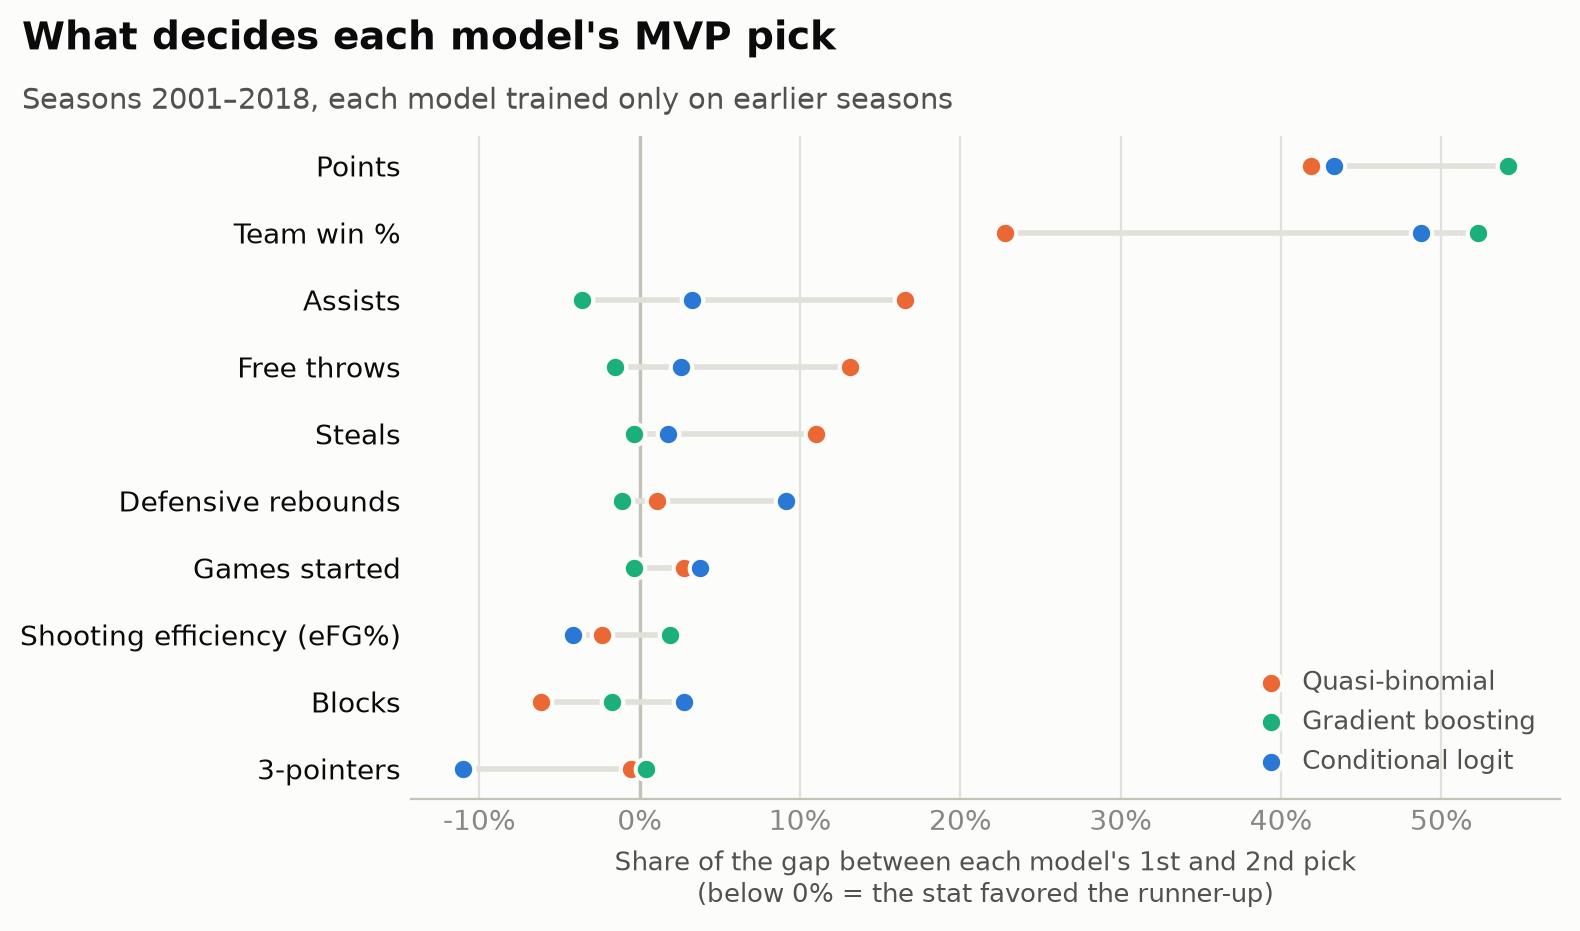

In [31]:
MODEL_COLORS = {'Quasi-binomial': ORANGE, 'Gradient boosting': AQUA, 'Conditional logit': BLUE}

def plot_deciding(shares, main, sub, fname):
    shares = shares.loc[shares.mean(axis=1).sort_values().index] * 100     #biggest on top
    fig, ax = new_chart((8, 4.8))
    ax.axvline(0, color=AXIS, linewidth=1.2, zorder=1)
    for i, feat in enumerate(shares.index):                                 #gray bar = how much the models disagree
        ax.plot([shares.loc[feat].min(), shares.loc[feat].max()], [i, i], color=GRID, linewidth=2, zorder=1)
    for name, color in MODEL_COLORS.items():
        ax.scatter(shares[name], range(len(shares)), s=60, color=color, edgecolor=SURFACE,
                   linewidth=1.5, zorder=3, label=name)
    ax.set_yticks(range(len(shares)))
    ax.set_yticklabels([label(f) for f in shares.index], color=INK)
    ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
    ax.set_xlabel("Share of the gap between each model's 1st and 2nd pick\n(below 0% = the stat favored the runner-up)",
                  color=INK2, fontsize=9.5)
    ax.legend(loc='lower right', frameon=False, fontsize=9.5, labelcolor=INK2, handletextpad=0.2)
    add_titles(fig, main, sub)
    fig.tight_layout(rect=(0, 0, 1, 0.87))
    fig.savefig(OUT / fname, facecolor=SURFACE)
    plt.show()

plot_deciding(shares, "What decides each model's MVP pick",
              'Seasons 2001–2018, each model trained only on earlier seasons', 'deciding_stats.png')

Team win % and points decide most picks in every model (together ~65% of the margin for the quasi-binomial and ~92–106% for the other two). The two better pickers lean much harder on winning (gradient boosting ~52%, conditional logit ~49%) than the quasi-binomial (~23%), which spreads the decision across assists, free throws and steals. The conditional logit also marks down 3-point volume (about −11%). Our reading: the quasi-binomial learns what gets a player *any* votes, while the conditional logit learns what separates #1 from #2.

In [32]:
#one season, all three models: right -> MVP vs the model's own runner-up; wrong -> model's pick vs the real MVP
def plot_case(yr, fname=None):
    g = data[data['Year'] == yr]
    mvp = g['MVP'].idxmax()
    season = f"{yr}–{str(yr + 1)[-2:]}"
    diffs, titles, n_hits = {}, {}, 0
    for name in short:
        ranked = g[models[name]].sort_values(ascending=False).index
        pick = ranked[0]
        if pick == mvp:
            rival, mark = ranked[1], '✓'
            n_hits += 1
        else:
            rival, mark = mvp, '✗'
        titles[name] = f"{name} {mark}\npicked {g.loc[pick, 'Player']}\nover {g.loc[rival, 'Player']}"
        c = contributions(yr, name)
        diffs[name] = c.loc[pick] - c.loc[rival]
    diffs = pd.DataFrame(diffs)
    #same stat order in every panel with biggest combined effect on top
    order = diffs.abs().div(diffs.abs().max()).sum(axis=1).sort_values().index

    fig, axes = plt.subplots(1, 3, figsize=(11, 4.6), sharey=True, dpi=200)
    fig.patch.set_facecolor(SURFACE)
    for ax, name in zip(axes, short):
        ax.set_facecolor(SURFACE)
        for side in ['top', 'right', 'left', 'bottom']:
            ax.spines[side].set_visible(False)
        ax.tick_params(length=0, colors=INK)
        ax.set_xticks([])                                    #units differ by model, so no shared scale!
        ax.axvline(0, color=AXIS, linewidth=1.2)
        d = diffs.loc[order, name]
        ax.barh(range(len(d)), d, height=0.6, color=[ORANGE if v > 0 else BLUE for v in d])
        ax.set_title(titles[name], fontsize=10, color=INK, loc='left')
    axes[0].set_yticks(range(len(order)))
    axes[0].set_yticklabels([label(f) for f in order])
    add_titles(fig, f"How each model picked the {season} MVP",
               f"Real MVP: {g.loc[mvp, 'Player']}. {n_hits} of 3 models picked him")
    fig.text(0.02, 0.02, "Orange = stat favored the model's pick; blue = favored the player it beat. "
             "Bar sizes compare within a model only (units differ by model)", fontsize=9, color=INK2)
    fig.tight_layout(rect=(0, 0.05, 1, 0.84))
    fig.savefig(OUT / (fname or f'how_picked_{yr}.png'), facecolor=SURFACE)
    plt.show()

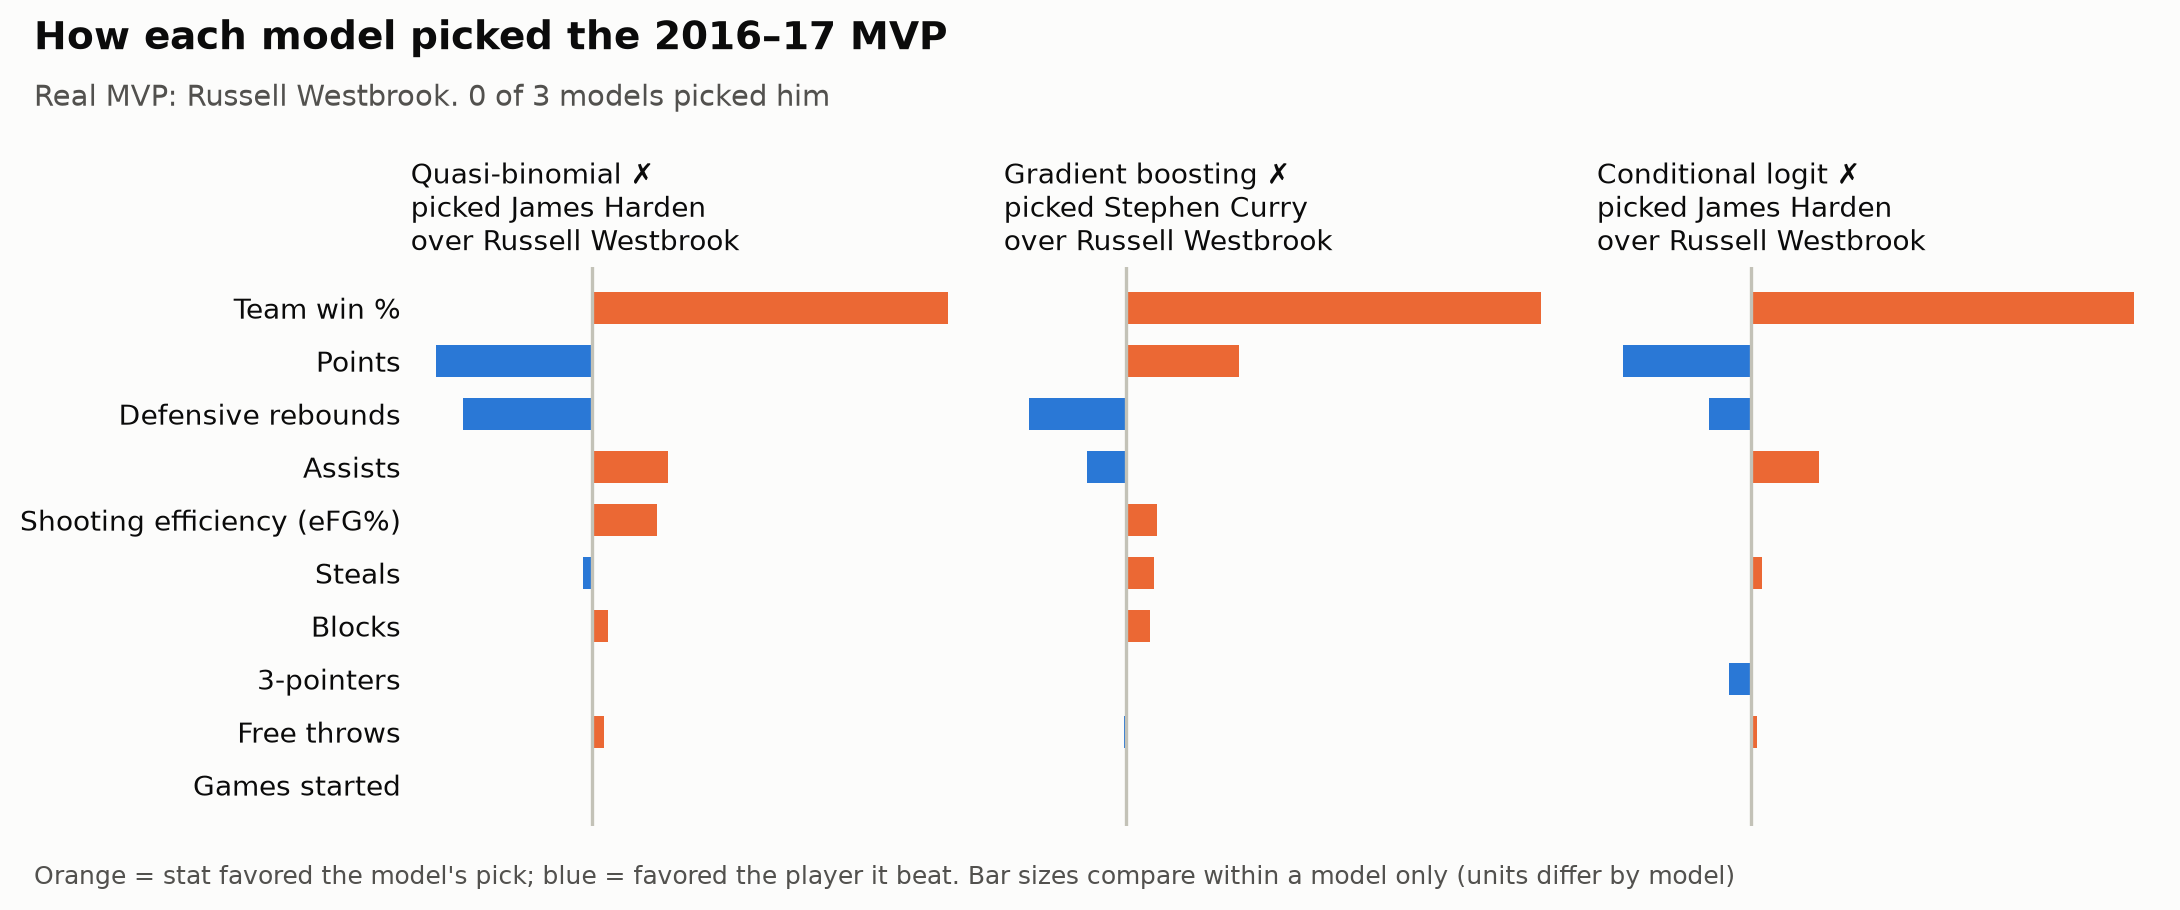

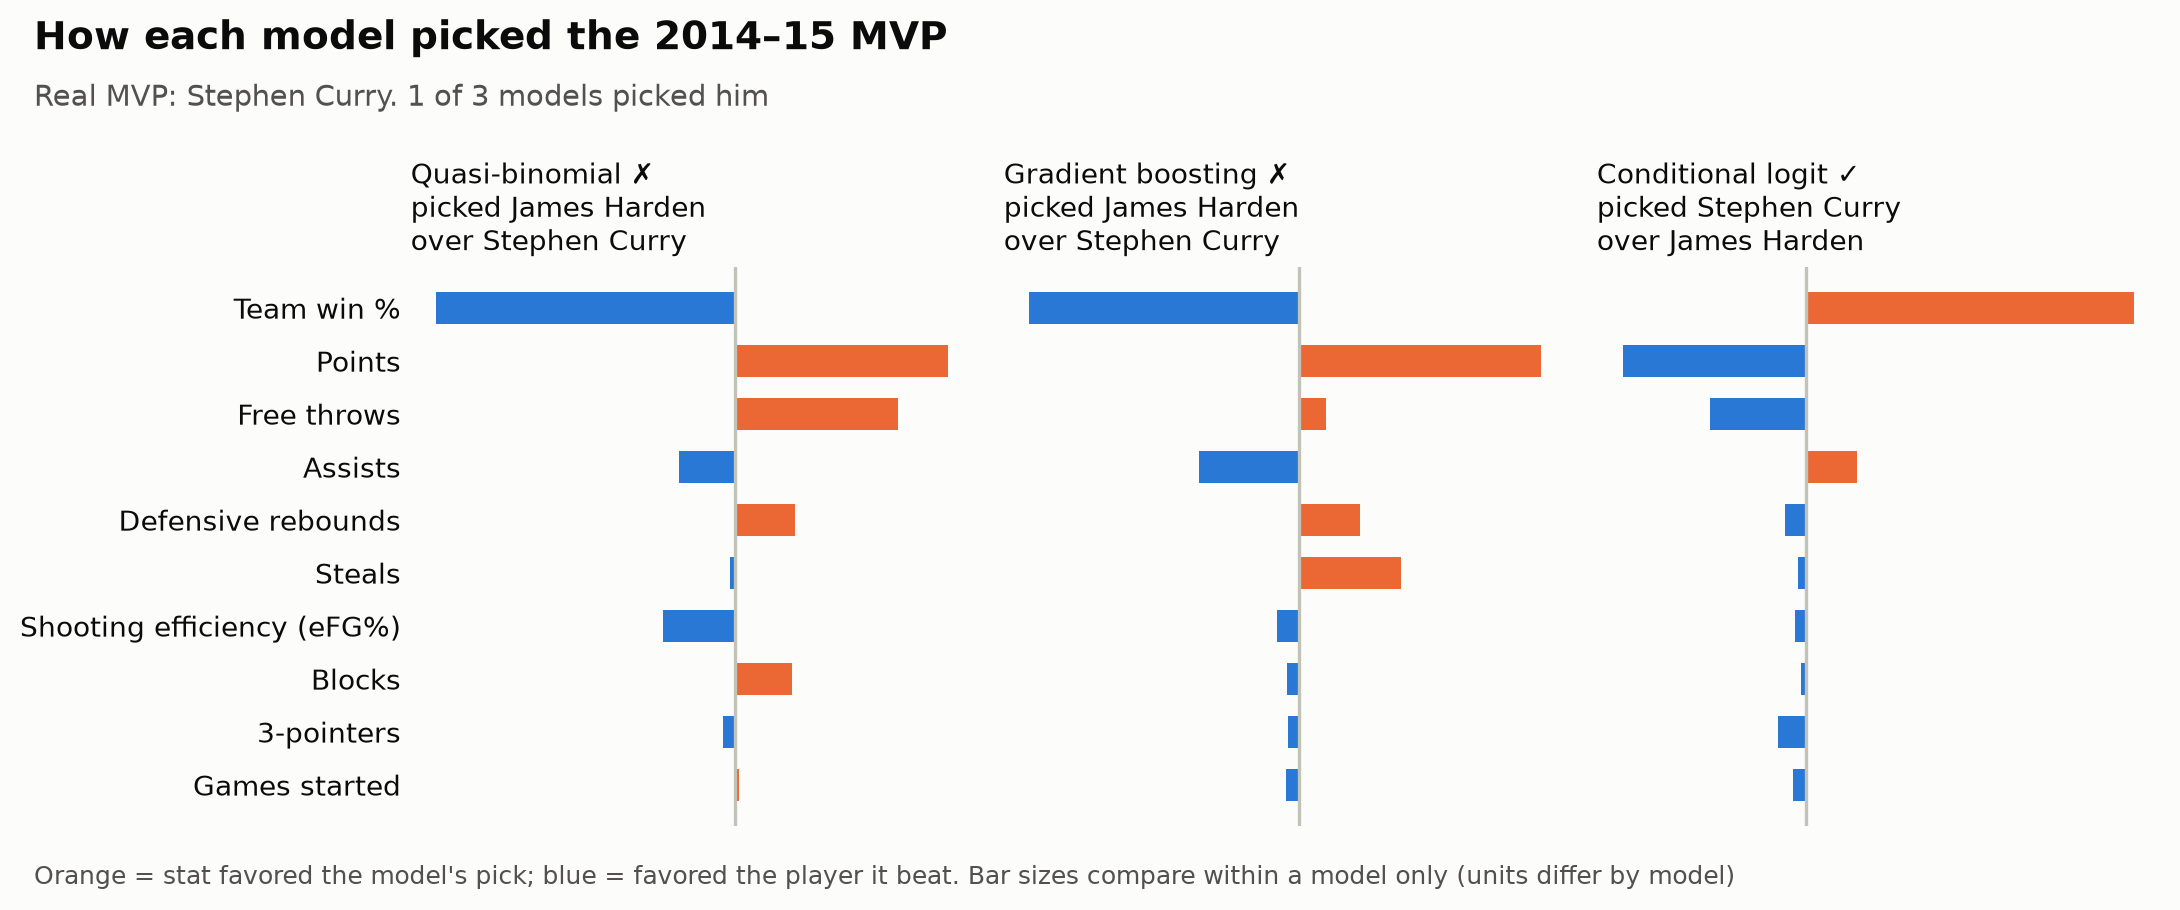

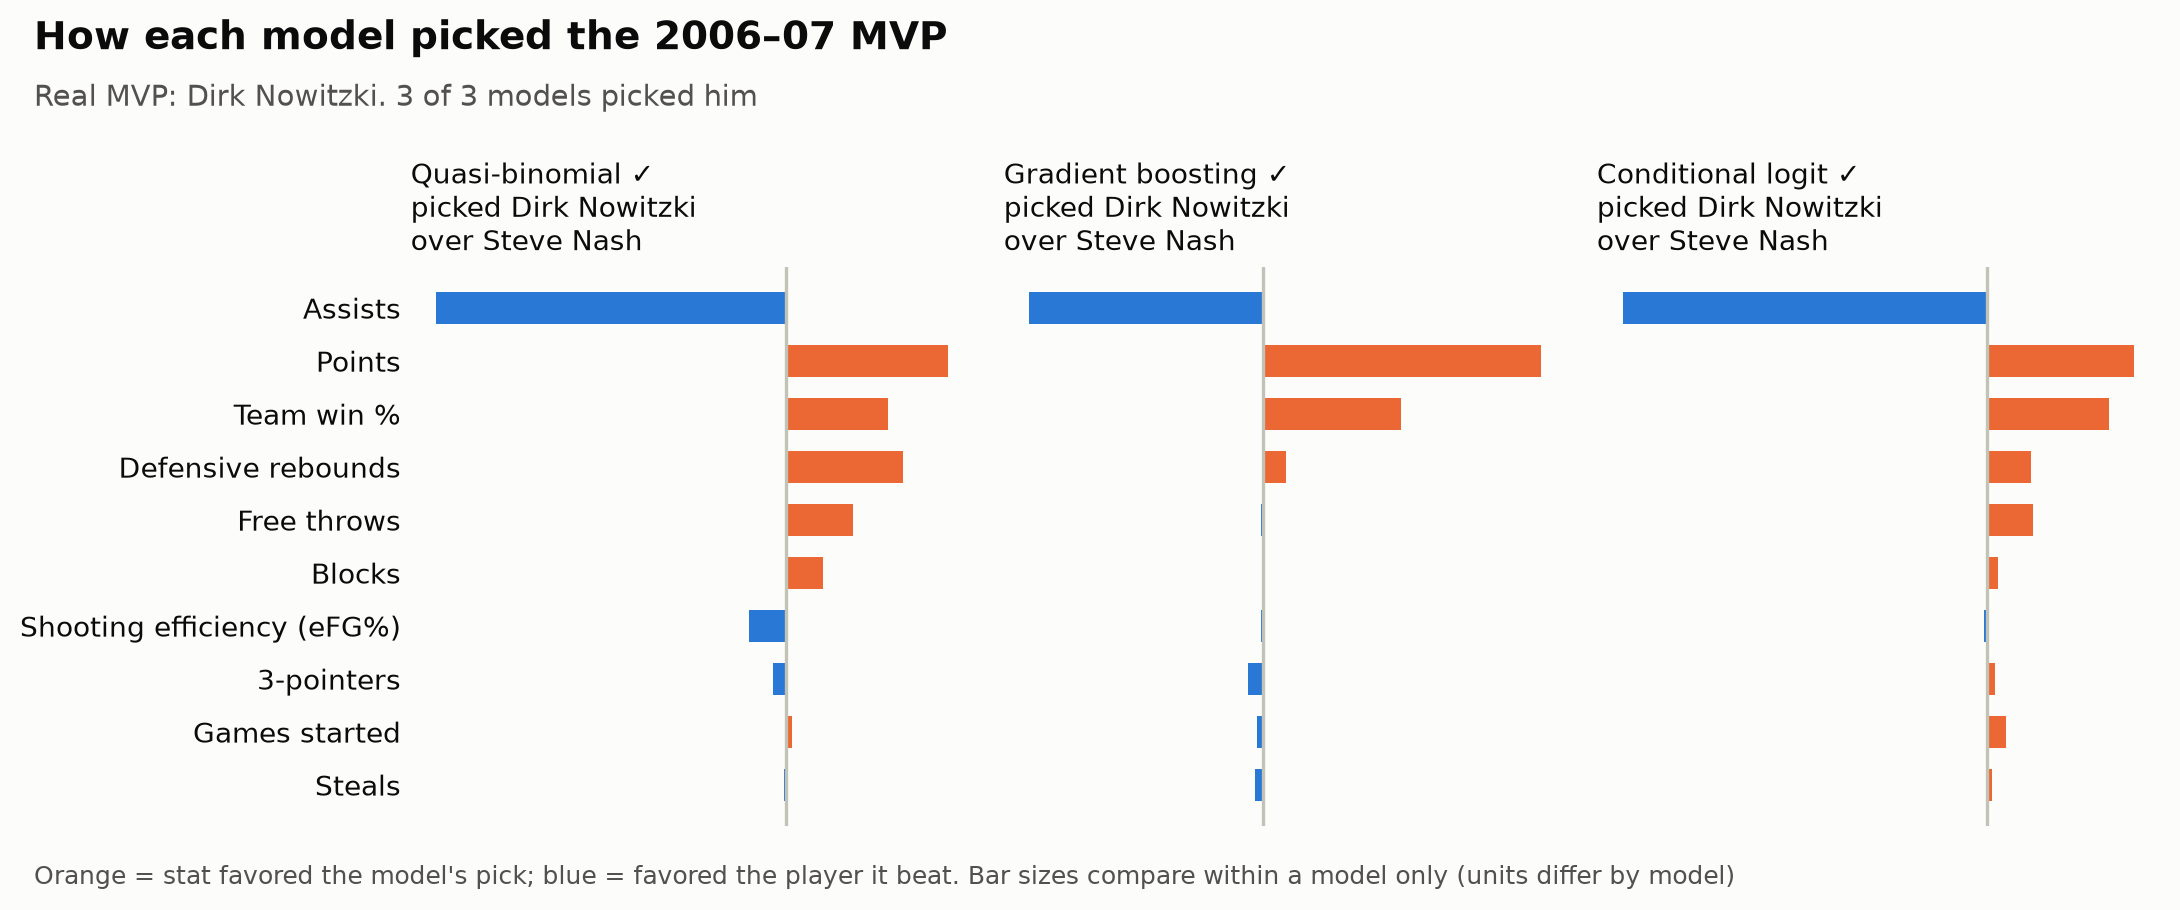

In [33]:
#seasons we can use in the slides: 2016-17 (all three missed), 2014-15 (1 of 3 right), 2006-07 (all right, mirrors Nash 2004-05)
for yr in [2016, 2014, 2006]:
    plot_case(yr)

Orange bars favored the model's pick, blue bars favored the player it beat. Bar sizes only compare within a model.
- **2016–17:** team win % (Rockets over Thunder) outweighed Westbrook's points and rebounds in all three models.
- **2014–15:** only the conditional logit picked Curry, almost entirely on team win %. The quasi-binomial and gradient boosting both picked Harden on his scoring (plus free throws in the quasi-binomial), even though win % favored Curry in all three.
- **2006–07:** Dirk over Nash in every model, the same pattern as 2004–05, when voters chose Nash instead.